# Estudo 02 – H1: existe reversão à média dentro do pregão?

Hipótese H1 das [notas](../NOTAS.md). A EDA do grupo encontrou **razão de variâncias VR(60) = 0,89** no WIN: os movimentos de 60 minutos seriam ~11% "menores" do que a soma de 60 movimentos de 1 minuto sugere, o que indicaria **reversão à média** (o preço desfaz parte do que andou). Se for real e grande, é exatamente o tipo de estrutura que uma previsão T+1 poderia explorar.

Perguntas:

1. O que é a razão de variâncias e como ela se liga à autocorrelação do Estudo 01?
2. O VR(60) = 0,89 é real ou é um artefato da forma de calcular?
3. Medido do jeito certo, com erro-padrão robusto, há reversão? Ela é estável ano a ano?
4. Há alguma estrutura escondida? (spoiler: sim, ligada ao **relógio**)
5. Ela é grande o bastante para pagar o custo?

**Dados:** WIN, candles de 1 min, **só até 31/12/2024** (período de desenvolvimento). Retornos sempre **dentro do pregão** (nunca atravessando a noite).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA))
import tt1_comum as t
sys.path.append(str(PASTA / "frentes" / "estatistico"))
import custos as cu                                   # modelo de custo (cenários 2,5 / 7,5 / 12,5 pts)

rng = np.random.default_rng(7)
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]
dia = pd.Series(win.index.normalize(), index=win.index)
r1 = np.log(win.close).diff()
r1[dia != dia.shift()] = np.nan                      # 1º minuto do dia: sem retorno (não atravessa a noite)
print(f"{len(win):,} candles de 1 min, {dia.nunique()} pregões, {win.index[0].date()} → {win.index[-1].date()}")


def vr_acf(x, grupo, q):
    '''Razão de variâncias VR(q) pelas autocorrelações, só com pares dentro do mesmo grupo (pregão).
    Devolve VR, z clássico (supõe retornos independentes) e z robusto (Lo-MacKinlay, aceita volatilidade variando).'''
    x = np.asarray(x, float); g = np.asarray(grupo)
    xc = x - np.nanmean(x); n = np.sum(~np.isnan(xc)); den = np.nansum(xc ** 2)
    vr, theta = 1.0, 0.0
    for k in range(1, q):
        a, b = xc[k:], xc[:-k]
        ok = ~np.isnan(a) & ~np.isnan(b) & (g[k:] == g[:-k])
        rho_k = (a[ok] * b[ok]).sum() / den * n / ok.sum()
        delta_k = n * (a[ok] ** 2 * b[ok] ** 2).sum() / den ** 2
        vr += 2 * (1 - k / q) * rho_k
        theta += (2 * (1 - k / q)) ** 2 * delta_k
    theta_iid = 2 * (2 * q - 1) * (q - 1) / (3 * q)
    return vr, (vr - 1) / np.sqrt(theta_iid / n), (vr - 1) / np.sqrt(theta / n)

513,736 candles de 1 min, 934 pregões, 2020-10-15 → 2024-12-30


## 1. O que é a razão de variâncias

**Ideia:** num passeio aleatório, os retornos de cada minuto são independentes, então a variância **soma**: a variância do retorno de q minutos é q vezes a variância do retorno de 1 minuto.

$$VR(q) = \frac{\text{Var}(\text{retorno de } q \text{ minutos})}{q \cdot \text{Var}(\text{retorno de 1 minuto})}$$

| VR(q) | Interpretação |
|---|---|
| = 1 | passeio aleatório: os minutos não se influenciam |
| < 1 | **reversão:** os movimentos se compensam, e o preço anda menos do que a soma dos minutos sugere |
| > 1 | **momentum:** os movimentos se reforçam |

**Ligação com o Estudo 01:** a VR é uma soma ponderada das autocorrelações de todas as defasagens até q − 1:

$$VR(q) = 1 + 2\sum_{k=1}^{q-1}\left(1 - \frac{k}{q}\right)\rho_k$$

Ou seja, VR(60) = 0,89 exige que as autocorrelações de 1 a 59 minutos somem (com pesos) cerca de −0,055. Cada ρₖ pode ser minúsculo, mas 59 deles juntos podem pesar. É por isso que a VR é uma ferramenta mais sensível que olhar só ρ₁.

Três processos simulados, cada um com 200 mil "minutos":

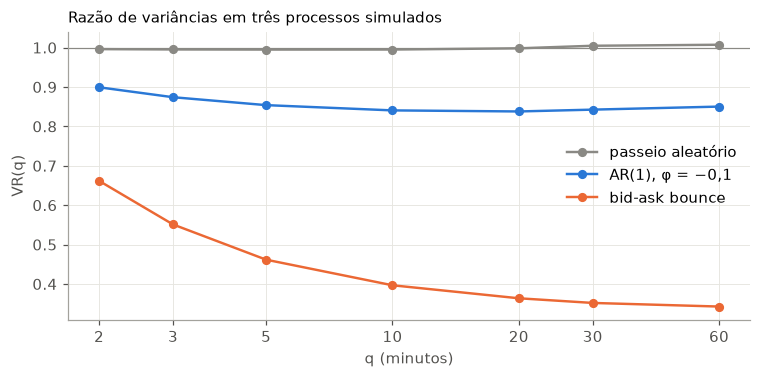

In [2]:
n = 200_000
e = rng.standard_normal(n)
ar = np.zeros(n)
for i in range(1, n):
    ar[i] = -0.1 * ar[i - 1] + e[i]                                  # AR(1) com φ = −0,1 (reversão)
preco_justo = np.cumsum(rng.standard_normal(n))
bounce = np.diff(preco_justo + 1.0 * rng.choice([-1, 1], n))          # "bid-ask bounce": negócio ora na compra, ora na venda
processos = {"passeio aleatório": rng.standard_normal(n), "AR(1), φ = −0,1": ar, "bid-ask bounce": bounce}

qs = [2, 3, 5, 10, 20, 30, 60]
fig, ax = plt.subplots(figsize=(8, 3.4))
for (nome, x), cor in zip(processos.items(), [CINZA, AZUL, LARANJA]):
    g = np.zeros(len(x))
    ax.plot(qs, [vr_acf(x, g, q)[0] for q in qs], "o-", color=cor, ms=5, label=nome)
ax.axhline(1, color=CINZA, lw=0.8); ax.set_xscale("log"); ax.set_xticks(qs, [str(q) for q in qs]); ax.minorticks_off()
ax.set_xlabel("q (minutos)"); ax.set_ylabel("VR(q)"); ax.legend(frameon=False)
ax.set_title("Razão de variâncias em três processos simulados", loc="left", fontsize=10); plt.show()

**Leitura:** o passeio aleatório fica em 1 em qualquer horizonte. O AR(1) negativo e o *bid-ask bounce* ficam abaixo de 1, ou seja, reversão. No bounce, a "reversão" é mecânica: o preço justo é um passeio aleatório, mas o preço negociado pula entre a ponta de compra e a de venda. Isso parece reversão nos dados, mas não dá para lucrar com ela: quem tenta paga exatamente esse spread.

## 2. O VR(60) = 0,89 é real?

A EDA calculou: variância dos retornos de candles de 60 min (fechamento → fechamento, dentro do dia) ÷ (60 × variância dos retornos de 1 min). Reproduzindo:

In [3]:
def ret_intradia(close):
    r = np.log(close).diff(); d = pd.Series(close.index.date, index=close.index)
    return r[d.eq(d.shift())].dropna()

def vr_como_eda(df, k):
    b = df.resample(f"{k}min").agg({"open": "first", "close": "last"}).dropna()
    return ret_intradia(b.close).var() / (k * ret_intradia(df.close).var())

for k in [15, 60]:
    print(f"VR({k}) calculado como na EDA, dados até 2024: {vr_como_eda(win, k):.3f}")

VR(15) calculado como na EDA, dados até 2024: 0.939
VR(60) calculado como na EDA, dados até 2024: 0.922


Esse cálculo tem dois problemas que **empurram a VR para baixo mesmo sem nenhuma reversão**:

1. **A primeira hora do dia sai do numerador, mas não do denominador.** O candle de 60 min das 9h não tem "fechamento anterior" dentro do dia, então é descartado. No 1 min, só o primeiro minuto é descartado. E a primeira hora é a **mais volátil do dia** (o perfil em "L" da EDA). O numerador perde a parte mais agitada do pregão; o denominador não.
2. **O último candle "de 60 min" tem só 24 minutos** (18:00–18:24) e é tratado como se tivesse 60. Ele tem naturalmente menos variância.

**Teste decisivo:** simular um passeio aleatório **sem nenhuma reversão**, mas com o perfil de volatilidade intradiária do WIN (cada minuto do dia com o desvio-padrão real daquele minuto), e aplicar o mesmo cálculo.

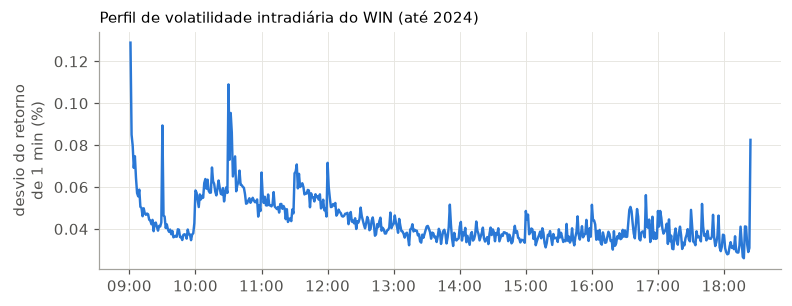

passeio aleatório simulado SEM reversão → VR(15) como na EDA = 0.970   (verdade: 1,000)
passeio aleatório simulado SEM reversão → VR(60) como na EDA = 0.940   (verdade: 1,000)


In [4]:
# perfil de volatilidade: desvio-padrão real do retorno de 1 min em cada horário (só dias de pregão completo até 18:24)
fim = win.groupby(dia).apply(lambda d: d.index.max().strftime("%H:%M"))
dias_ok = fim[fim == "18:24"].index
base = pd.DataFrame({"r": r1, "hm": win.index.strftime("%H:%M"), "dia": dia})
perfil = base[base.dia.isin(dias_ok)].groupby("hm").r.std().dropna()
minutos = pd.to_datetime(perfil.index, format="%H:%M")

# 1000 pregões simulados: passeio aleatório puro, volatilidade seguindo o perfil (sem nenhuma autocorrelação)
D = 1000
ret_sim = rng.standard_normal((D, len(perfil))) * perfil.values
idx = pd.DatetimeIndex([pd.Timestamp("2030-01-01") + pd.Timedelta(days=d) + pd.Timedelta(hours=m.hour, minutes=m.minute)
                        for d in range(D) for m in minutos])
preco_sim = pd.DataFrame({"close": 100_000 * np.exp(np.cumsum(ret_sim.ravel()))}, index=idx)
preco_sim["open"] = preco_sim.close

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(minutos, perfil.values * 100, color=AZUL)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax.set_ylabel("desvio do retorno\nde 1 min (%)"); ax.set_title("Perfil de volatilidade intradiária do WIN (até 2024)", loc="left", fontsize=10)
plt.show()
for k in [15, 60]:
    print(f"passeio aleatório simulado SEM reversão → VR({k}) como na EDA = {vr_como_eda(preco_sim, k):.3f}   (verdade: 1,000)")

**Leitura:** um passeio aleatório **sem nenhuma reversão** já dá VR(60) = 0,94 com esse cálculo, contra 0,92 nos dados reais até 2024. Cerca de **3/4 da queda** (de 1 para 0,92) é **artefato**: vem do perfil de volatilidade e dos candles incompletos, não do comportamento do preço.

Corrigindo os dois problemas nos dados reais (usar só candles completos, e o 1 min só nos mesmos minutos cobertos por eles):

In [5]:
def vr_corrigido(df, r, k):
    lbl = df.index.floor(f"{k}min")
    g = pd.DataFrame({"c": df.close.values, "r": r.values, "lbl": lbl, "dia": df.index.normalize()})
    a = g.groupby("lbl").agg(c=("c", "last"), n=("c", "size"), dia=("dia", "first"))
    a["rk"] = np.log(a.c).diff(); a.loc[a.dia != a.dia.shift(), "rk"] = np.nan
    cheio = a[(a.n == k) & a.rk.notna()]                                 # só candles completos
    mesmos_minutos = g[g.lbl.isin(cheio.index)].r.dropna()               # 1 min nos mesmos horários
    return cheio.rk.var() / (k * mesmos_minutos.var())

for k in [15, 60]:
    print(f"VR({k}): como na EDA {vr_como_eda(win, k):.3f}  →  corrigido {vr_corrigido(win, r1, k):.3f}")

VR(15): como na EDA 0.939  →  corrigido 0.973


VR(60): como na EDA 0.922  →  corrigido 0.992


## 3. Medindo direito: VR pelas autocorrelações, com erro-padrão robusto

Uma forma mais limpa de calcular é usar a fórmula da Seção 1, com as autocorrelações medidas **só em pares de minutos do mesmo pregão**. Assim não há candle incompleto nem janela descartada.

Para saber se a diferença para 1 é ruído, usamos o **teste de Lo e MacKinlay (1988)**. A estatística z mede quantos erros-padrão a VR está longe de 1. Há duas versões:

- **z clássico:** supõe retornos independentes e de volatilidade constante. É a régua 2/√n do Estudo 01.
- **z robusto:** aceita volatilidade variando no tempo (o agrupamento de volatilidade). É a versão que vale para mercado (Estudo 01, Seção 6).

|z| > 2 → significativo a ~5%.

In [6]:
linhas = []
for q in [2, 5, 10, 15, 30, 60, 120]:
    vr, z_cl, z_rob = vr_acf(r1.values, dia.values, q)
    linhas.append(dict(q_min=q, VR=vr, z_classico=z_cl, z_robusto=z_rob))
pd.DataFrame(linhas).round(3)

,q_min,VR,z_classico,z_robusto
0,2,0.996,-2.558,-0.918
1,5,0.991,-2.921,-1.172
2,10,0.984,-3.419,-1.533
3,15,0.981,-3.157,-1.520
4,30,0.980,-2.270,-1.237
5,60,0.985,-1.223,-0.744
6,120,0.985,-0.856,-0.572


**Leitura:**

- Medida direito, a VR fica entre **0,98 e 0,99**: uma reversão bem menor que a sugerida pelo 0,89.
- Com a régua clássica, ela pareceria significativa em vários horizontes. **Com a robusta, nenhum horizonte passa de |z| = 2.** É o mesmo padrão do Estudo 01: o agrupamento de volatilidade faz a régua clássica exagerar.

Um efeito real deveria aparecer em todo ano. Por ano:

In [7]:
linhas = []
for ano in range(2020, 2025):
    m = win.index.year == ano
    for q in [15, 60]:
        vr, _, z = vr_acf(r1.values[m], dia.values[m], q)
        linhas.append(dict(ano=ano, q=q, VR=vr, z_robusto=z))
pd.DataFrame(linhas).pivot(index="ano", columns="q").round(3)

VR        z_robusto       
q        15     60        15     60
ano                                
2020  1.053  0.995     1.657 -0.084
2021  0.997  0.979    -0.106 -0.459
2022  0.960  1.001    -2.215  0.037
2023  0.957  0.950    -1.784 -1.202
2024  1.001  0.993     0.044 -0.205

**Leitura:** o sinal muda de ano para ano (2020 tem VR(15) acima de 1), e só 2022 passa de |z| = 2 em VR(15). Não há uma reversão estável no **agregado**.

**Conclusão parcial de H1:** a "reversão intradiária" da EDA é, em grande parte, artefato do cálculo. Medida corretamente, ela é pequena, não significativa e instável.

## 4. A estrutura escondida: o relógio de 5 minutos

Ao testar a versão "de trading" da pergunta (*o retorno dos últimos 5 minutos prevê o dos próximos 5?*), apareceu algo estranho: **o resultado depende de onde a janela começa no relógio.**

Em cada minuto do pregão calculamos o retorno dos 5 minutos anteriores e dos 5 seguintes, e separamos pela "fase", ou seja, o minuto da decisão módulo 5 (fase 0 = decisões em :00, :05, :10…).

In [8]:
lp = np.log(win.close).values
pos = win.groupby(dia).cumcount().values
n_dia = win.groupby(dia).close.transform("size").values
minuto = win.index.minute.values
ano = win.index.year.values

def corr_passado_futuro(sel, m=5, h=5):
    '''Correlação entre o retorno dos últimos m minutos e o dos próximos h, nos minutos selecionados, com z robusto.'''
    i = np.where(sel & (pos >= m) & (pos + h < n_dia))[0]
    p = lp[i] - lp[i - m]; f = lp[i + h] - lp[i]
    p, f = p - p.mean(), f - f.mean()
    rho = (p * f).sum() / np.sqrt((p * p).sum() * (f * f).sum())
    z = (p * f).sum() / np.sqrt((p * p * f * f).sum())
    return rho, z, len(i)

linhas = [dict(fase=f, **dict(zip(["rho", "z_robusto", "n"], corr_passado_futuro(minuto % 5 == f)))) for f in range(5)]
pd.DataFrame(linhas).round(4)

,fase,rho,z_robusto,n
0,0,-0.0228,-4.1834,100857
1,1,-0.0189,-3.6171,100853
2,2,-0.0016,-0.3183,100870
3,3,0.0004,0.0716,100906
4,4,-0.0015,-0.2693,100910


Nas fases 0 e 1 há reversão (ρ ≈ −0,02, |z| ≈ 3,5–4). Nas fases 2, 3 e 4, nada.

**Primeira hipótese: notícias.** Dados econômicos saem em horários redondos (9:30, 10:00, 10:30 de Brasília); o preço dispara e depois devolve parte. Se fosse isso, o efeito estaria concentrado em :00 e :30. Teste:

In [9]:
grupos = {"decisões em :00/:01 e :30/:31": np.isin(minuto, [0, 1, 30, 31]),
          "decisões em :15/:16 e :45/:46": np.isin(minuto, [15, 16, 45, 46]),
          "demais marcas de 5 min (+1)": np.isin(minuto, [5, 6, 10, 11, 20, 21, 25, 26, 35, 36, 40, 41, 50, 51, 55, 56]),
          "fora das marcas (fases 2, 3, 4)": np.isin(minuto % 5, [2, 3, 4])}
pd.DataFrame([dict(grupo=k, **dict(zip(["rho", "z_robusto", "n"], corr_passado_futuro(s)))) for k, s in grupos.items()]).round(4)

,grupo,rho,z_robusto,n
0,decisões em :00/:01 e :30/:31,-0.0246,-2.7396,32704
1,decisões em :15/:16 e :45/:46,-0.0317,-3.4400,34576
2,demais marcas de 5 min (+1),-0.0173,-3.7152,134430
3,"fora das marcas (fases 2, 3, 4)",-0.0009,-0.2874,302686


**A hipótese das notícias cai:** o efeito aparece em **todas** as marcas de 5 minutos, não só nas redondas. É uma estrutura do **relógio**, não do calendário de notícias.

Para ver de onde vem, a correlação entre o retorno de 1 min da barra j e o da barra j + k, separando pela posição da barra j no ciclo de 5 minutos (z robusto entre parênteses):

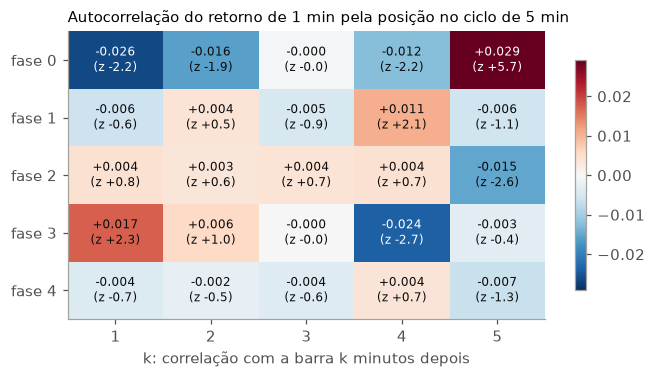

desvio do retorno de 1 min por fase (relativo à média): {0: 1.067, 1: 1.025, 2: 0.979, 3: 0.963, 4: 0.962}


In [10]:
x = (r1 - r1.mean()).values; g = dia.values; fase = minuto % 5
tab_rho, tab_z = {}, {}
for f in range(5):
    for k in range(1, 6):
        a, b = x[:-k], x[k:]
        ok = (fase[:-k] == f) & ~np.isnan(a) & ~np.isnan(b) & (g[:-k] == g[k:])
        tab_rho[(f, k)] = np.corrcoef(a[ok], b[ok])[0, 1]
        tab_z[(f, k)] = (a[ok] * b[ok]).sum() / np.sqrt((a[ok] ** 2 * b[ok] ** 2).sum())
R = pd.Series(tab_rho).unstack(); Z = pd.Series(tab_z).unstack()
R.index.name, R.columns.name = "fase da barra j", "k (minutos depois)"

fig, ax = plt.subplots(figsize=(7, 3.4))
lim = np.abs(R.values).max()
im = ax.imshow(R.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{R.values[i, j]:+.3f}\n(z {Z.values[i, j]:+.1f})", ha="center", va="center", fontsize=8,
                color="white" if abs(R.values[i, j]) > 0.6 * lim else "#0b0b0b")
ax.set_xticks(range(5), [str(k) for k in range(1, 6)]); ax.set_yticks(range(5), [f"fase {f}" for f in range(5)])
ax.set_xlabel("k: correlação com a barra k minutos depois"); ax.grid(False)
ax.set_title("Autocorrelação do retorno de 1 min pela posição no ciclo de 5 min", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

desvio_fase = pd.Series(x).groupby(fase).std() / np.nanstd(x)
print("desvio do retorno de 1 min por fase (relativo à média):", desvio_fase.round(3).to_dict())

**Leitura** (fase 0 = barras terminadas em :x0 e :x5):

- A barra da marca de 5 min é **~7% mais volátil** que as outras.
- O movimento dela é **parcialmente devolvido** nos 1–2 minutos seguintes (ρ = −0,026 e −0,016).
- Ela tem correlação **positiva** com a barra da **próxima** marca, 5 minutos depois (ρ = +0,029, z = 5,7). Esse z sobrevive com folga à correção para as 25 comparações da tabela (o limiar de Bonferroni seria ~3,1).

**Interpretação provável:** participantes que agem num relógio de 5 minutos, como algoritmos de execução que fatiam ordens grandes em intervalos fixos (TWAP) ou operadores de gráfico de 5 min agindo no fechamento do candle. Cada fatia empurra o preço na mesma direção a cada marca (correlação positiva entre marcas), e entre as marcas o preço devolve parte do empurrão (reversão). É um efeito de **microestrutura**: vem da forma como as ordens chegam, não de informação sobre o valor do índice.

Por ano (correlação dos últimos 5 min com os próximos 5, decisões nas fases 0 e 1 contra as fases 2–4):

In [11]:
linhas = []
for a in range(2020, 2025):
    r01, z01, _ = corr_passado_futuro(np.isin(minuto % 5, [0, 1]) & (ano == a))
    r24, z24, _ = corr_passado_futuro(np.isin(minuto % 5, [2, 3, 4]) & (ano == a))
    linhas.append(dict(ano=a, rho_fase01=r01, z_fase01=z01, rho_fase234=r24, z_fase234=z24))
pd.DataFrame(linhas).round(4)

,ano,rho_fase01,z_fase01,rho_fase234,z_fase234
0,2020,0.0004,0.0334,0.0051,0.4639
1,2021,-0.0217,-2.7619,0.0054,0.7904
2,2022,-0.0323,-4.9481,-0.0054,-1.0409
3,2023,-0.0188,-2.3087,-0.0118,-1.6160
4,2024,-0.0007,-0.0964,0.0060,0.8390


**Leitura:** o efeito é forte em 2021–2023 e **some em 2020 e 2024**. É real, mas **não é permanente**. Se for de algoritmos, depende de quem está operando em cada época, e um efeito desses tende a desaparecer quando fica conhecido.

## 5. Dá dinheiro?

Estratégia mais direta: depois de uma barra da marca de 5 min, apostar **contra** o movimento dela e sair 1, 2 ou 5 minutos depois. Para operar só nos movimentos grandes, medimos o tamanho da barra em desvios da volatilidade recente (z = retorno ÷ desvio dos últimos 30 minutos, calculado só com o passado). O resultado é o ganho **bruto** em pontos por operação, que é o **custo de equilíbrio**: o maior custo que a estratégia aguentaria sem perder dinheiro. Ele é comparado com os três cenários de custo (`custos.py`; [notas](../NOTAS.md), Seção 4.7): otimista 2,5 pts (só taxas, ordens limitadas), **base 7,5 pts** (ordens a mercado), conservador 12,5 pts (com slippage).

In [12]:
c = win.close.values
vol = pd.Series(r1.values).rolling(30, min_periods=20).std().shift(1).values
zbar = r1.values / vol
linhas = []
for H in [1, 2, 5]:
    fut = np.full(len(c), np.nan)
    mesmo_dia = (dia.shift(-H) == dia).values
    fut[:-H] = c[H:] - c[:-H]; fut[~mesmo_dia] = np.nan
    for lim in [0, 1, 2]:
        for nome, msk in [("barra da marca de 5 min", fase == 0), ("demais barras", fase != 0)]:
            s = msk & (np.abs(zbar) > lim) & ~np.isnan(fut) & ~np.isnan(zbar)
            ganho = -np.sign(zbar[s]) * fut[s]
            linhas.append(dict(sair_em_min=H, z_minimo=lim, barra=nome, n=s.sum(),
                               custo_equilibrio_pts=ganho.mean(), erro_padrao=ganho.std() / np.sqrt(s.sum())))
g = pd.DataFrame(linhas)
g.round(2)

,sair_em_min,z_minimo,barra,n,custo_equilibrio_pts,erro_padrao
0,1,0,barra da marca de 5 min,96870,0.96,0.18
1,1,0,demais barras,387097,-0.48,0.09
2,1,1,barra da marca de 5 min,31985,1.11,0.34
3,1,1,demais barras,115012,-0.54,0.17
4,1,2,barra da marca de 5 min,7465,1.68,0.84
5,1,2,demais barras,24510,-0.24,0.45
6,2,0,barra da marca de 5 min,96870,1.34,0.24
7,2,0,demais barras,386232,-0.34,0.12
8,2,1,barra da marca de 5 min,31985,2.09,0.45
9,2,1,demais barras,114734,-0.66,0.24


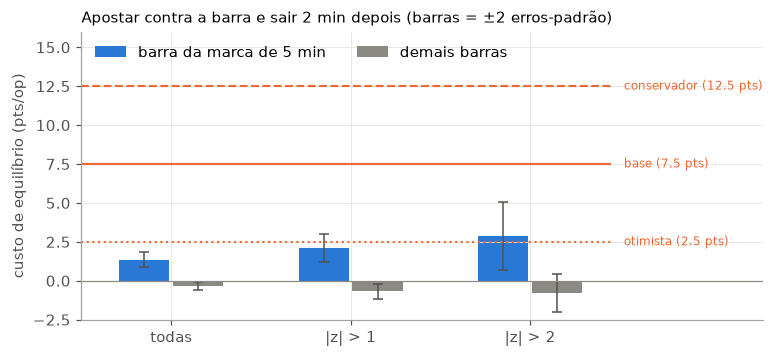

In [13]:
sub = g[g.sair_em_min == 2]
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, (nome, cor) in enumerate([("barra da marca de 5 min", AZUL), ("demais barras", CINZA)]):
    d = sub[sub.barra == nome]
    xs = np.arange(len(d)) + (j - 0.5) * 0.3
    ax.bar(xs, d.custo_equilibrio_pts, width=0.28, color=cor, label=nome)
    ax.errorbar(xs, d.custo_equilibrio_pts, yerr=2 * d.erro_padrao, fmt="none", color="#52514e", lw=1, capsize=3)
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    c_pts = cu.CENARIOS[nome]["custo_pts"]
    ax.hlines(c_pts, -0.5, 2.45, color=LARANJA, lw=1.4, ls=estilo)
    ax.text(2.5, c_pts, f" {nome} ({c_pts:g} pts)", color=LARANJA, va="center", fontsize=8)
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_xticks(range(3), ["todas", "|z| > 1", "|z| > 2"]); ax.set_ylabel("custo de equilíbrio (pts/op)")
ax.set_xlim(-0.5, 3.3); ax.set_ylim(-2.5, 16); ax.legend(frameon=False, loc="upper left", ncol=2)
ax.set_title("Apostar contra a barra e sair 2 min depois (barras = ±2 erros-padrão)", loc="left", fontsize=10)
plt.show()

**Leitura:**

- Contra a barra da marca de 5 min, o custo de equilíbrio é **positivo e significativo**: +1,3 pt no geral e +2,9 ± 1,1 pts depois de movimentos grandes (|z| > 2). Fica **bem abaixo do cenário base (7,5 pts)** e do conservador.
- Só depois de movimentos grandes ele chega perto do **cenário otimista (2,5 pts)**. Mas o otimista supõe ordens limitadas, e esta é a estratégia em que elas funcionam pior: uma ordem limitada **contra** o movimento tende a ser executada justamente quando o movimento continua (**seleção adversa**), e não é executada quando ele reverte. Não é lucrativo como estratégia isolada.
- Nas demais barras o sinal é o **oposto**: uma leve continuação (apostar contra perde ~0,3–0,8 pt).
- **Uso prático possível: execução, não sinal.** Quem já vai operar por outro motivo pode ganhar 1–3 pts de preço evitando entrar logo depois de uma barra forte da marca de 5 min na mesma direção, ou esperando 1–2 minutos. Em operações que ganham pouco por vez, 1–3 pts não é desprezível.

## 6. Conclusões de H1

| Pergunta | Resposta |
|---|---|
| VR(60) = 0,89 é reversão real? | **Em grande parte, não.** É artefato: a primeira hora (a mais volátil) sai do numerador, e o candle das 18h tem só 24 min. Um passeio aleatório simulado com o perfil de volatilidade do WIN reproduz ~3/4 do efeito; corrigido, VR(60) = 0,99 |
| Medida direito, há reversão no agregado? | VR ≈ 0,98–0,99; **nenhum horizonte é significativo** com erro-padrão robusto; o sinal muda entre os anos |
| Há estrutura escondida? | **Sim:** um ciclo de 5 minutos do relógio. A barra da marca é mais volátil, é parcialmente devolvida em 1–2 min e se correlaciona com a próxima marca. Forte em 2021–2023, ausente em 2020 e 2024 |
| Paga o custo? | **Não:** custo de equilíbrio de 1–3 pts, contra 7,5 pts no cenário base. Só encosta no otimista (2,5) depois de movimentos grandes, e esse cenário é o menos crível para uma estratégia de reversão (seleção adversa). Pode servir para **execução** (quando entrar), não como sinal |

**Lições que valem para o projeto todo:**

1. **O jeito de calcular pode criar o efeito.** Perfil intradiário, candles incompletos e fronteiras do dia distorcem estatísticas simples. Sempre testar o método num caso simulado em que a resposta é conhecida.
2. **O alinhamento dos candles importa.** Um candle de 5 min que começa em :00 e outro que começa em :02 enxergam estruturas diferentes. Isso afeta diretamente a ideia de "testar todas as discretizações": diferenças entre 5, 7 ou 10 min podem vir do alinhamento com o relógio de 5 min, não de uma escala "certa".
3. **Exploramos muitos cortes** (fases, grupos de horário, anos, limiares). A estrutura de 5 min sobrevive com folga (z = 5,7), mas foi **encontrada explorando**: se for usada, precisa ser confirmada na segunda validação (2025 → 03/2026).

### Para ir além (opcional)

- Repetir no WDO: o ciclo de 5 min também existe lá?
- Ver se o efeito se concentra em certos horários (abertura?) ou dias (vencimento?). Isso já entra em H3.
- Ler sobre microestrutura e algoritmos de execução: Harris, *Trading and Exchanges* (cap. sobre custos e impacto de ordens).